# Week 1 solution: Linear and logistic regression

This notebook answers **both parts** of the Week 1 housing assignment using the original CSV. Part A predicts `sale_price_eur`; Part B predicts `high_price` (sale price at least €500,000). It includes inspection, cleaning, EDA, train/test splits, models, metrics, and interpretation.

Run from the `ml` folder. Required packages: `numpy`, `pandas`, `matplotlib`, `scikit-learn`. The file is `data/house_pricing_ml_exercise.csv`. The displayed results come from one reproducible 80/20 split and can differ from another solution that uses different cleaning choices.

## 1. Define the questions and inspect the raw data

A **regression** model predicts a number (price). A **classification** model predicts a class (`high_price` 0 or 1). `house_id` is an identifier, and neither target may be used to predict the other.

In [6]:
import numpy as np
import pandas as pd
from pathlib import Path
raw_path = Path('data/house_pricing_ml_exercise.csv')
raw = pd.read_csv(raw_path)
print('Raw shape:', raw.shape)
print('Exact duplicate properties ignoring house_id:',
      raw.duplicated(subset=[c for c in raw.columns if c != 'house_id']).sum())
display(raw.head())
display(pd.DataFrame({'dtype': raw.dtypes.astype(str), 'missing': raw.isna().sum(),
                      'question marks': raw.astype(str).eq('?').sum()}))

Raw shape: (1208, 19)
Exact duplicate properties ignoring house_id: 8


,house_id,city,neighborhood,property_type,bedrooms,bathrooms,living_area_sqm,lot_size_sqm,year_built,condition,parking_spaces,distance_city_center_km,school_rating_1_10,crime_rate_1_10,has_garden,has_balcony,energy_rating,sale_price_eur,high_price
0,H0001,Frankfurt,Westend,Apartment,3,1,79.2,0,2004,Excellent,1,1.5,6.6,2.6,No,No,D,675000,1
1,H0002,Frankfurt,Gallus,Terraced House,5,2,127.3,514.9,1979,Average,2,4.1,7.4,3.6,No,Yes,D,716000,1
2,H0003,Frankfurt,Bockenheim,Apartment,2,1,45.8 sqm,0,2004,Needs Renovation,0,4.2,8.7,4.3,No,Yes,A+,266000,0
3,H0004,Hamburg,Harburg,Terraced House,5,2,182.5,529.9,2019,Needs Renovation,2,20.2,8.9,4.2,Yes,Yes,C,622000,1
4,H0005,Cologne,Sülz,Detached House,3,1,98.1,507.0,1979,Good,1,0.4,7.5,4.2,Yes,Yes,B,780000,1


,dtype,missing,question marks
house_id,str,0,0
city,str,0,0
neighborhood,str,0,0
property_type,str,0,0
bedrooms,str,17,5
bathrooms,str,18,4
living_area_sqm,str,27,10
lot_size_sqm,str,36,11
year_built,str,26,11
condition,str,28,3


## 2. Clean the data

- Remove duplicate properties while ignoring their unique `house_id`; duplicate copies could otherwise enter both training and test sets.
- Turn `?`, `n/a`, blanks and malformed numeric entries into missing values. Extract the numeric part from entries like `1 baths` and `90m2`.
- Standardize capitalization, spaces, common typos and Yes/No spellings.
- **Keep** unusual prices until there is evidence they are errors. A zero lot size can be valid for an apartment.
- Later, median/most-frequent imputation and one-hot encoding will be fitted **only on training data** by the pipeline.

These are explicit, simple corrections for this exercise; any new data source would need its own data audit.

In [7]:
from pathlib import Path
import numpy as np
import pandas as pd

DATA_PATH = Path('data/house_pricing_ml_exercise.csv')
if not DATA_PATH.exists():
    raise FileNotFoundError('Run this notebook from the ml folder so data/house_pricing_ml_exercise.csv is available.')

numeric_features = [
    'bedrooms', 'bathrooms', 'living_area_sqm', 'lot_size_sqm', 'year_built',
    'parking_spaces', 'distance_city_center_km', 'school_rating_1_10',
    'crime_rate_1_10', 'has_garden', 'has_balcony',
]
categorical_features = ['city', 'neighborhood', 'property_type', 'condition', 'energy_rating']


def load_housing():
    df = pd.read_csv(DATA_PATH, na_values=['?', 'n/a', 'NA', ''])
    # Remove repeated properties before splitting, so copies cannot appear in both sets.
    df = df.drop_duplicates(subset=[c for c in df.columns if c != 'house_id']).copy()
    for col in numeric_features[:-2]:
        # Handles entries such as "1 baths" and "90m2"; invalid entries become NaN.
        numbers = df[col].astype('string').str.extract(r'(-?\d+(?:\.\d+)?)', expand=False)
        df[col] = pd.to_numeric(numbers, errors='coerce')
    for col in ['has_garden', 'has_balcony']:
        values = df[col].astype('string').str.strip().str.lower()
        df[col] = values.map({'yes': 1, 'y': 1, 'true': 1, '1': 1,
                              'no': 0, 'n': 0, 'false': 0, '0': 0}).astype(float)
    for col in categorical_features:
        clean = df[col].astype('string').str.strip().str.lower()
        df[col] = clean.astype(object).where(clean.notna(), np.nan)
    df['city'] = df['city'].replace({
        'berln': 'berlin', 'colgne': 'cologne', 'koeln': 'cologne',
        'frankfrut': 'frankfurt', 'hambug': 'hamburg',
        'leipzg': 'leipzig', 'münich': 'munich',
    })
    df['property_type'] = df['property_type'].replace({
        'apartmnt': 'apartment', 'detached': 'detached house',
        'detatched house': 'detached house', 'semi detached': 'semi-detached',
        'semi-detatched': 'semi-detached', 'terrace house': 'terraced house',
        'terraced hse': 'terraced house',
    })
    df['condition'] = df['condition'].replace({
        'averge': 'average', 'excelent': 'excellent', 'gud': 'good',
        'needs renovaton': 'needs renovation', 'renovation needed': 'needs renovation',
    })
    df['energy_rating'] = df['energy_rating'].replace({'dd': 'd'})
    df['sale_price_eur'] = pd.to_numeric(df['sale_price_eur'], errors='coerce')
    df['high_price'] = pd.to_numeric(df['high_price'], errors='coerce')
    return df.dropna(subset=['sale_price_eur', 'high_price']).reset_index(drop=True)

housing = load_housing()
print(f'{len(housing)} houses; {housing.high_price.mean():.1%} are high priced')
print('Target matches EUR 500,000 rule:',
      bool(((housing.sale_price_eur >= 500_000).astype(int) == housing.high_price).all()))

1200 houses; 63.4% are high priced
Target matches EUR 500,000 rule: True


In [8]:
print('Clean shape:', housing.shape)
display(housing[numeric_features + ['sale_price_eur']].describe().T[['min', '25%', '50%', '75%', 'max']].round(1))
display(housing[numeric_features + categorical_features].isna().sum().sort_values(ascending=False).head(12).to_frame('missing after cleaning'))
print('Zero lot sizes:', int((housing.lot_size_sqm == 0).sum()))
print('Highest sale price:', f'€{housing.sale_price_eur.max():,.0f}')

Clean shape: (1200, 19)


,min,25%,50%,75%,max
bedrooms,1.0,2.0,3.0,4.0,7.0
bathrooms,1.0,1.0,1.0,2.0,4.0
living_area_sqm,28.0,78.6,106.1,145.8,260.8
lot_size_sqm,0.0,0.0,90.0,445.3,1017.2
year_built,1950.0,1969.0,1988.0,2006.0,2025.0
parking_spaces,0.0,0.0,1.0,2.0,3.0
distance_city_center_km,0.3,2.7,4.5,7.0,23.3
school_rating_1_10,1.5,6.1,7.1,8.1,10.0
crime_rate_1_10,0.5,3.3,4.4,5.5,10.0
has_garden,0.0,0.0,0.0,1.0,1.0


,missing after cleaning
lot_size_sqm,47
crime_rate_1_10,40
year_built,37
living_area_sqm,37
school_rating_1_10,36
distance_city_center_km,36
energy_rating,34
condition,31
bathrooms,22
bedrooms,22


Zero lot sizes: 555
Highest sale price: €2,645,000


## 3. Explore the data

Plots and summaries help us understand the data before modelling. Correlation describes association, not causation. We inspect prices, living area, and differences across cities and property types.

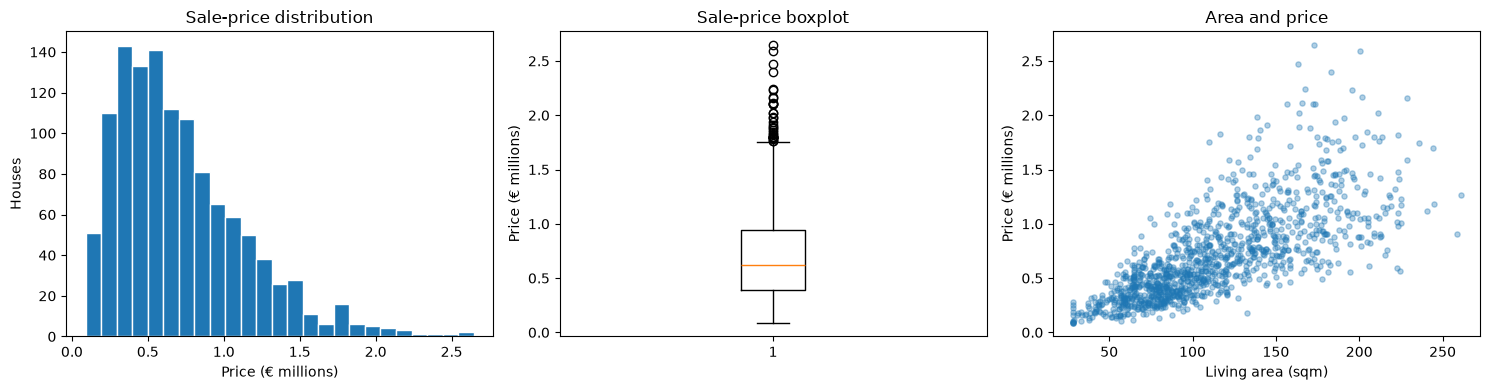

Numerical correlations with sale price:


,correlation
living_area_sqm,0.730
bedrooms,0.618
lot_size_sqm,0.604
bathrooms,0.422
parking_spaces,0.415
has_garden,0.408
year_built,0.099
has_balcony,0.061
school_rating_1_10,0.041
crime_rate_1_10,-0.077


Median sale price by city:


,median price (€)
city,
munich,1040000.0
hamburg,653500.0
frankfurt,600500.0
berlin,574000.0
cologne,569000.0
leipzig,370000.0


Median sale price by property_type:


,median price (€)
property_type,
semi-detached,948000.0
detached house,935000.0
terraced house,878500.0
apartment,393000.0


Median sale price by condition:


,median price (€)
condition,
average,648000.0
good,623500.0
excellent,610000.0
needs renovation,569000.0
NaN,523000.0


In [5]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(housing.sale_price_eur / 1_000_000, bins=25, edgecolor='white')
axes[0].set(title='Sale-price distribution', xlabel='Price (€ millions)', ylabel='Houses')
axes[1].boxplot(housing.sale_price_eur.dropna() / 1_000_000)
axes[1].set(title='Sale-price boxplot', ylabel='Price (€ millions)')
axes[2].scatter(housing.living_area_sqm, housing.sale_price_eur / 1_000_000, alpha=.35, s=14)
axes[2].set(title='Area and price', xlabel='Living area (sqm)', ylabel='Price (€ millions)')
plt.tight_layout()
plt.show()

correlations = housing[numeric_features + ['sale_price_eur']].corr(numeric_only=True)['sale_price_eur'].drop('sale_price_eur').sort_values(ascending=False)
print('Numerical correlations with sale price:')
display(correlations.round(3).to_frame('correlation'))
for col in ['city', 'property_type', 'condition']:
    print(f'Median sale price by {col}:')
    display(housing.groupby(col, dropna=False)['sale_price_eur'].median().sort_values(ascending=False).round(0).to_frame('median price (€)'))

## 4. Make one honest train/test split

We hold out 20% of houses for evaluation. Both tasks use the same rows. Stratifying by the class keeps the class proportions similar. `high_price` is excluded from price inputs because it was made from price. `sale_price_eur` is excluded from classification inputs for the same reason.

In [9]:
from sklearn.model_selection import train_test_split
feature_columns = numeric_features + categorical_features
X = housing[feature_columns]
y_price = housing['sale_price_eur']
y_high = housing['high_price'].astype(int)
train_rows, test_rows = train_test_split(
    np.arange(len(housing)), test_size=.20, random_state=42, stratify=y_high
)
X_train, X_test = X.iloc[train_rows], X.iloc[test_rows]
price_train, price_test = y_price.iloc[train_rows], y_price.iloc[test_rows]
high_train, high_test = y_high.iloc[train_rows], y_high.iloc[test_rows]
assert {'sale_price_eur', 'high_price', 'house_id'}.isdisjoint(X.columns)
print('Training rows:', len(X_train), '| Test rows:', len(X_test))
print('High-price share: train', round(high_train.mean(), 3), '| test', round(high_test.mean(), 3))

Training rows: 960 | Test rows: 240
High-price share: train 0.634 | test 0.633


## 5. Preprocess inside each model

Numerical missing values get the **training median**; categorical missing values get the **training mode**. Categorical values become one-hot indicators. We drop one category per field so a linear coefficient can be compared with a reference category. Numerical fields are standardized, so each numeric coefficient represents roughly a one-standard-deviation change.

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def make_preprocessor(numeric_columns=numeric_features, categorical_columns=categorical_features):
    return ColumnTransformer([
        ('numbers', Pipeline([
            ('impute', SimpleImputer(strategy='median')),
            ('scale', StandardScaler()),
        ]), numeric_columns),
        ('categories', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('encode', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=2, drop='first')),
        ]), categorical_columns),
    ])

## Part A: Linear regression for sale price

Fit only on the training rows. Report MAE and RMSE in euros (lower is better) and R² (higher is better).

In [11]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

linear = Pipeline([
    ('prepare', make_preprocessor()),
    ('model', LinearRegression()),
])
linear.fit(X_train, price_train)
price_pred = linear.predict(X_test)
price_metrics = pd.Series({
    'MAE (€)': mean_absolute_error(price_test, price_pred),
    'RMSE (€)': np.sqrt(mean_squared_error(price_test, price_pred)),
    'R²': r2_score(price_test, price_pred),
}, name='Linear regression')
display(price_metrics.to_frame().round(3))
print(f'On this test set, the average absolute price error is €{price_metrics["MAE (€)"]:,.0f}.')

/home/tunde/.local/share/mamba/envs/ml-course/lib/python3.12/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


,Linear regression
MAE (€),99006.332
RMSE (€),135727.487
R²,0.891


On this test set, the average absolute price error is €99,006.


### Which features matter for price?

First inspect coefficients. For standardized numeric inputs, a coefficient is the predicted euro change for a one-standard-deviation increase, holding other inputs fixed. Categorical coefficients compare with an omitted reference category. Because some features overlap (for example, area and bedrooms), coefficients are **associations**, not causal effects or a definitive importance ranking.

Then use permutation importance: shuffle one **original** feature at a time on the test set and measure how much MAE gets worse. Larger positive values suggest the model relied more on that feature. Correlated features can share importance.

In [12]:
coefficient_names = linear.named_steps['prepare'].get_feature_names_out()
coefficient_table = pd.DataFrame({
    'feature': coefficient_names,
    'coefficient (€)': linear.named_steps['model'].coef_,
})
print('Numeric coefficients (per one training SD):')
display(coefficient_table[coefficient_table.feature.str.startswith('numbers__')]
        .sort_values('coefficient (€)', key=abs, ascending=False).round(0))
print('Largest categorical coefficients relative to reference categories:')
display(coefficient_table[coefficient_table.feature.str.startswith('categories__')]
        .sort_values('coefficient (€)', key=abs, ascending=False).head(10).round(0))

Numeric coefficients (per one training SD):


,feature,coefficient (€)
2,numbers__living_area_sqm,223843.0
3,numbers__lot_size_sqm,60569.0
6,numbers__distance_city_center_km,-37622.0
4,numbers__year_built,32073.0
7,numbers__school_rating_1_10,23831.0
8,numbers__crime_rate_1_10,-20852.0
5,numbers__parking_spaces,16226.0
0,numbers__bedrooms,11349.0
10,numbers__has_balcony,9457.0
9,numbers__has_garden,4165.0


Largest categorical coefficients relative to reference categories:


,feature,coefficient (€)
17,categories__neighborhood_bogenhause,490497.0
15,categories__city_munich,299343.0
14,categories__city_leipzig,-272939.0
52,categories__neighborhood_spandau,-268958.0
57,categories__neighborhood_westend,264284.0
27,categories__neighborhood_giesin,-253154.0
33,categories__neighborhood_harbur,-248278.0
34,categories__neighborhood_harburg,-234491.0
39,categories__neighborhood_maxvorstadt,211538.0
18,categories__neighborhood_bogenhausen,193563.0


In [13]:
from sklearn.inspection import permutation_importance
import warnings
# The same expected unseen-neighborhood warning would repeat for every shuffle.
with warnings.catch_warnings():
    warnings.filterwarnings('ignore', message='Found unknown categories in columns')
    price_importance = permutation_importance(
        linear, X_test, price_test, scoring='neg_mean_absolute_error',
        n_repeats=5, random_state=42, n_jobs=1
    )
price_imp = pd.DataFrame({
    'feature': X_test.columns,
    'MAE increase when shuffled (€)': price_importance.importances_mean,
}).sort_values('MAE increase when shuffled (€)', ascending=False)
display(price_imp.head(10).round(0))
print('Features with the largest positive MAE increase:',
      ', '.join(price_imp.loc[price_imp['MAE increase when shuffled (€)'] > 0, 'feature'].head(5)))

,feature,MAE increase when shuffled (€)
2,living_area_sqm,179213.0
11,city,122331.0
12,neighborhood,84294.0
14,condition,22062.0
3,lot_size_sqm,20817.0
13,property_type,16689.0
4,year_built,10301.0
6,distance_city_center_km,7736.0
15,energy_rating,5531.0
7,school_rating_1_10,3520.0


Features with the largest positive MAE increase: living_area_sqm, city, neighborhood, condition, lot_size_sqm


## Part B: Logistic regression for high-price classification

`high_price` is `1` when `sale_price_eur >= €500,000`. The classifier sees only property characteristics. A predicted probability of at least 0.5 becomes class 1.

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix)

logistic = Pipeline([
    ('prepare', make_preprocessor()),
    ('model', LogisticRegression(max_iter=2000)),
])
logistic.fit(X_train, high_train)
high_pred = logistic.predict(X_test)
classification_metrics = pd.Series({
    'Accuracy': accuracy_score(high_test, high_pred),
    'Precision': precision_score(high_test, high_pred),
    'Recall': recall_score(high_test, high_pred),
    'F1': f1_score(high_test, high_pred),
}, name='Logistic regression')
display(classification_metrics.to_frame().round(3))
cm = confusion_matrix(high_test, high_pred, labels=[0, 1])
display(pd.DataFrame(cm,
    index=['Actually low (0)', 'Actually high (1)'],
    columns=['Predicted low (0)', 'Predicted high (1)']))
print(f'False positives: {cm[0,1]} | False negatives: {cm[1,0]}')

/home/tunde/.local/share/mamba/envs/ml-course/lib/python3.12/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


,Logistic regression
Accuracy,0.929
Precision,0.941
Recall,0.947
F1,0.944


,Predicted low (0),Predicted high (1)
Actually low (0),79,9
Actually high (1),8,144


False positives: 9 | False negatives: 8


### Interpret the classification result

**Precision** asks how many predicted high-priced houses were truly high priced. **Recall** asks how many truly high-priced houses we found. The upper-right confusion-matrix cell is a false positive; the lower-left is a false negative. Logistic coefficients describe changes in log-odds, not direct changes in probability.

In [15]:
logistic_names = logistic.named_steps['prepare'].get_feature_names_out()
logistic_coefficients = pd.DataFrame({
    'feature': logistic_names,
    'log-odds coefficient': logistic.named_steps['model'].coef_[0],
})
logistic_coefficients['odds ratio'] = np.exp(logistic_coefficients['log-odds coefficient'])
display(logistic_coefficients.sort_values('log-odds coefficient', key=abs,
        ascending=False).head(12).round(3))
print('Odds ratio > 1 means higher estimated odds, holding other model inputs fixed.')

,feature,log-odds coefficient,odds ratio
2,numbers__living_area_sqm,2.863,17.514
15,categories__city_munich,2.819,16.763
14,categories__city_leipzig,-2.582,0.076
32,categories__neighborhood_grünau,-2.156,0.116
34,categories__neighborhood_harburg,-1.985,0.137
52,categories__neighborhood_spandau,-1.871,0.154
57,categories__neighborhood_westend,1.668,5.299
3,numbers__lot_size_sqm,1.657,5.244
35,categories__neighborhood_höchst,-1.567,0.209
56,categories__neighborhood_wandsbek,-1.432,0.239


Odds ratio > 1 means higher estimated odds, holding other model inputs fixed.


## Final answers and limits

- **Part A:** This run gives MAE about **€98,000**, RMSE about **€135,000**, and R² about **0.89**. The exact values appear above. The permutation table identifies which original features the fitted linear model used most on this split. Numeric coefficients are per standard deviation; categorical coefficients are relative to omitted categories.
- **Part B:** This run gives accuracy about **0.93**, precision about **0.94**, recall about **0.95**, and F1 about **0.94**. The exact values and confusion matrix appear above. Neither price nor a price-derived feature entered the classifier.
- **Limits:** These are results from one train/test split of a relatively small exercise dataset. Relationships are not causal. Week 3 will use cross-validation and baselines for a stronger check.